# 04 · Experiment E1 — pairwise encounters: rate × latency × geometry

**Questions.** RQ1 (how does AoI affect TTC estimation and alert timing) and
RQ2 (do update rates that suffice for tracking still suffice for *tactical*
conflict detection).

**Design.** Controlled two-aircraft encounters so the truth is known exactly.
Every configuration varies one factor family at a time against a fixed
geometry, per research plan §22. Monte-Carlo repetitions vary the seed only.

The detector is run twice over identical criteria — once on ground truth, once
on the surveillance store — so any difference is attributable to information
age and nothing else.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

from telemetry_freshness.viz import style as S, figures as F
S.use_paper_style()
print("working dir:", ROOT)

working dir: /path/to/Field_Measurement_of_Age_of_Information


In [2]:
from telemetry_freshness.simulation.encounters import EncounterSpec, synthetic_encounter
from telemetry_freshness.experiments.runner import ScenarioConfig, run_scenario
from telemetry_freshness.telemetry.network_model import TelemetryConfig
from telemetry_freshness.conflict.detector import ConflictCriteria

CRITERIA = ConflictCriteria(horizontal_separation_m=30.0, vertical_separation_m=15.0, horizon_s=30.0)
GEOMETRIES = ["head_on", "crossing", "converging", "overtaking"]
RATES_HZ   = [10, 5, 2, 1, 0.5]
LATENCY_MS = [0, 100, 250, 500, 1000]
N_SEEDS    = 12

print("separation standard:", CRITERIA)
print(f"{len(GEOMETRIES)}×{len(RATES_HZ)}×{len(LATENCY_MS)}×{N_SEEDS} = "
      f"{len(GEOMETRIES)*len(RATES_HZ)*len(LATENCY_MS)*N_SEEDS} runs")

separation standard: ConflictCriteria(horizontal_separation_m=30.0, vertical_separation_m=15.0, horizon_s=30.0, screen_range_m=5000.0)
4×5×5×12 = 1200 runs


### Encounter geometries

All four are designed to conflict (0 m nominal miss distance) so that recall is
measurable; the aircraft speeds differ per geometry to give a realistic spread
of closing speeds.

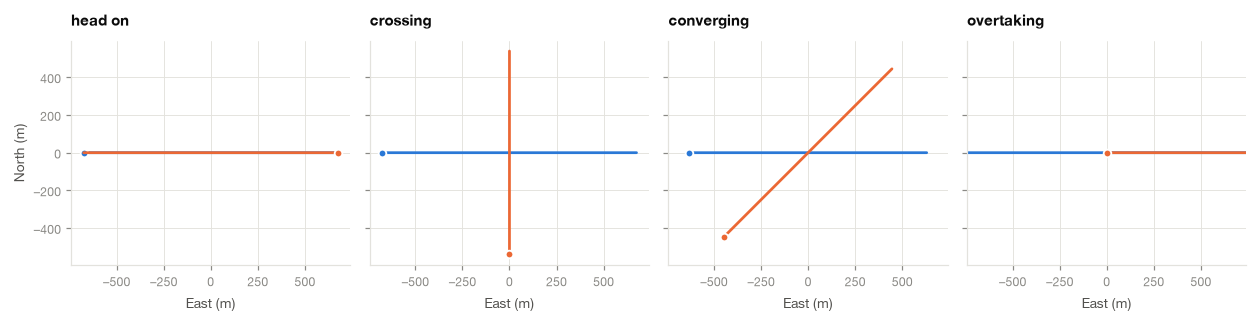

In [3]:
specs = {
    "head_on":    EncounterSpec("head_on",    speed_a_mps=15, speed_b_mps=15, lead_in_s=45, duration_s=90),
    "crossing":   EncounterSpec("crossing",   speed_a_mps=15, speed_b_mps=12, lead_in_s=45, duration_s=90),
    "converging": EncounterSpec("converging", speed_a_mps=14, speed_b_mps=14, lead_in_s=45, duration_s=90),
    "overtaking": EncounterSpec("overtaking", speed_a_mps=18, speed_b_mps=9,  lead_in_s=45, duration_s=90),
}
fig, axes = S.plt.subplots(1, 4, figsize=(11.5, 3.0), sharey=True)
for ax, (name, sp) in zip(axes, specs.items()):
    tr = synthetic_encounter(sp)
    for uid, c in zip(sorted(tr.uas_id.unique()), S.categorical_colors(2)):
        g = tr[tr.uas_id == uid]
        ax.plot(g.x_m, g.y_m, color=c, lw=1.8)
        ax.plot(g.x_m.iloc[0], g.y_m.iloc[0], marker="o", ms=5, color=c,
                markeredgecolor=S.INK["surface"], markeredgewidth=1.2)
    ax.set_title(name.replace("_", " ")); ax.set_aspect("equal", adjustable="datalim")
    ax.set_xlabel("East (m)")
axes[0].set_ylabel("North (m)")
S.finish(fig, axes); S.save(fig, "S8_encounter_geometries"); S.plt.show()

In [4]:
from itertools import product
runs = []
for geom, rate, lat_ms, seed in product(GEOMETRIES, RATES_HZ, LATENCY_MS, range(N_SEEDS)):
    traj = synthetic_encounter(specs[geom])
    cfg = ScenarioConfig(
        scenario_id=f"{geom}",
        telemetry=TelemetryConfig(update_rate_hz=rate, latency_ms=lat_ms,
                                  jitter_ms=0.1*lat_ms, latency_model="fixed"),
        criteria=CRITERIA, decision_rate_hz=5.0, seed=1000 + seed,
    )
    r = run_scenario(traj, cfg)
    if r.empty: continue
    r["encounter_type"] = geom
    r["seed_index"] = seed
    runs.append(r)

E1 = pd.concat(runs, ignore_index=True)
E1.to_parquet("results/raw/E1_pairwise_sweep.parquet", index=False)
print(f"{len(E1):,} (decision time, pair) records over {E1.groupby(['encounter_type','update_rate_hz','latency_ms','seed_index']).ngroups} runs")

540,000 (decision time, pair) records over 1200 runs


## Realised information age versus the configured rate — Figure F8

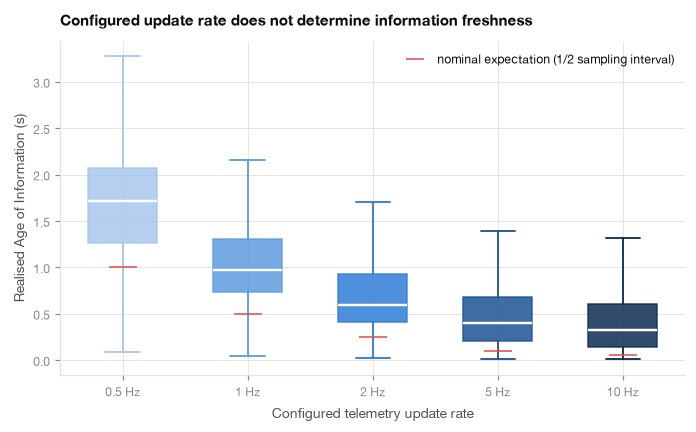

p50                           p95                        
latency_ms      0     100   250   500   1000  0     100   250   500   1000
update_rate_hz                                                            
0.5             1.40  1.50  1.65  1.90  2.40  1.94  2.05  2.20  2.45  2.98
1.0             0.70  0.80  0.95  1.20  1.71  0.97  1.07  1.22  1.50  2.03
2.0             0.35  0.45  0.60  0.85  1.36  0.49  0.59  0.75  1.02  1.58
5.0             0.12  0.24  0.40  0.65  1.16  0.20  0.30  0.47  0.73  1.30
10.0            0.06  0.16  0.32  0.58  1.08  0.10  0.20  0.37  0.65  1.20

In [5]:
fig, ax = F.fig_rate_vs_realised_aoi(E1)
S.save(fig, "F8_rate_vs_realised_aoi"); S.plt.show()

display(E1.groupby(["update_rate_hz","latency_ms"]).aoi_s
        .agg(p50="median", p95=lambda s: s.quantile(.95)).round(3).unstack().round(2))

The nominal expectation (half the sampling interval) only holds at zero added
latency. Once transport delay is present the realised age is dominated by it,
which is precisely why the paper reports AoI rather than update rate.

## Signed TTC error — Figure F3

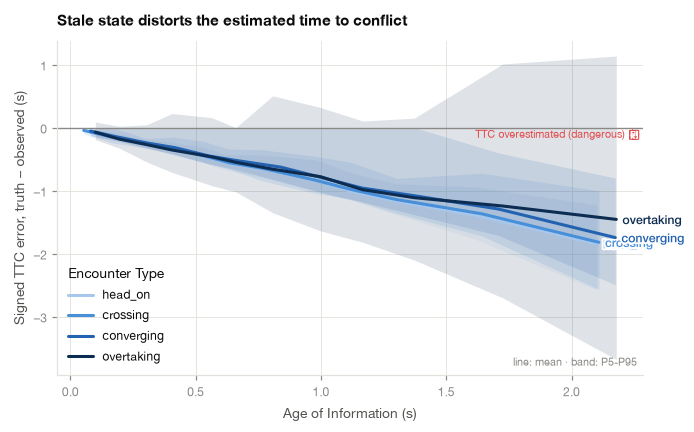

,n,mean,p05,frac_ttc_overestimated
encounter_type,,,,
converging,47818,-0.687,-1.712,0.935
crossing,46111,-0.712,-1.749,0.968
head_on,45204,-0.727,-1.771,0.985
overtaking,48643,-0.677,-2.310,0.807


Overall: 92.2% of comparable estimates overestimate TTC (mean -0.70 s).


In [6]:
fig, ax = F.fig_ttc_error_vs_aoi(E1, level_col="encounter_type")
S.save(fig, "F3_ttc_error_vs_aoi"); S.plt.show()

ttc = E1.dropna(subset=["ttc_error_signed_s"])
# signed = truth - observed, so NEGATIVE is the dangerous direction: the
# observed TTC exceeds reality and the system believes it has more time.
display(ttc.groupby("encounter_type").ttc_error_signed_s.agg(
    n="size", mean="mean", p05=lambda s: s.quantile(.05),
    frac_ttc_overestimated=lambda s: float((s < 0).mean())).round(3))
print(f"Overall: {(ttc.ttc_error_signed_s < 0).mean():.1%} of comparable estimates "
      f"overestimate TTC (mean {ttc.ttc_error_signed_s.mean():.2f} s).")

## Rate × latency grid — Figure F5

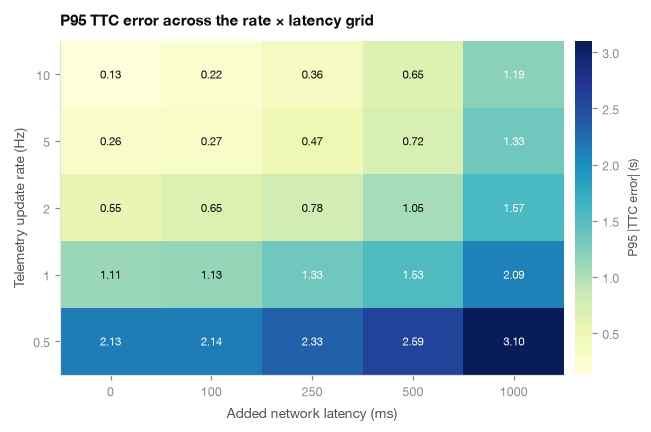

In [7]:
fig, ax = F.fig_rate_latency_heatmap(E1, value_col="ttc_error_abs_s", agg="p95")
S.save(fig, "F5_rate_latency_heatmap"); S.plt.show()

## Detection quality and alert timing

In [8]:
from telemetry_freshness.evaluation.metrics import recall_by_aoi, detection_counts
from telemetry_freshness.evaluation.timing import timing_table

overall = detection_counts(E1.conflict_truth, E1.conflict_observed)
display(pd.Series(overall.as_dict()).to_frame("all configurations").T)

rec = recall_by_aoi(E1)
display(rec[["aoi_bin","n","n_positive","recall","precision"]].round(3))
rec.to_csv("results/processed/E1_recall_by_aoi.csv", index=False)

,tp,fp,tn,fn,n,recall,precision,f1,false_negative_rate
all configurations,187776.0,3907.0,344093.0,4224.0,540000.0,0.978,0.979617,0.978808,0.022


,aoi_bin,n,n_positive,recall,precision
0,"[0.0, 0.1)",29604,10513,1.000,0.995
1,"[0.1, 0.25)",57394,20490,0.998,0.995
2,"[0.25, 0.5)",97581,34817,0.992,0.990
3,"[0.5, 0.75)",91178,32672,0.986,0.984
4,"[0.75, 1.0)",56126,20250,0.977,0.982
5,"[1.0, 1.5)",114806,41437,0.968,0.972
6,"[1.5, 2.0)",53950,19555,0.955,0.962
7,"[2.0, 3.0)",32550,11931,0.938,0.951
8,"[3.0, 5.0)",869,335,0.931,0.937


In [9]:
timing = timing_table(
    E1, group_cols=("encounter_type","update_rate_hz","latency_ms","seed_index","uas_a","uas_b"),
    separation_threshold_m=CRITERIA.horizontal_separation_m)
timing.to_parquet("results/raw/E1_timing.parquet", index=False)

t = timing.dropna(subset=["alert_lead_time_s"])
display(t.groupby(["update_rate_hz","latency_ms"]).agg(
    n=("alert_lead_time_s","size"),
    lead_p50=("alert_lead_time_s","median"),
    lead_p05=("alert_lead_time_s", lambda s: s.quantile(.05)),
    delay_p50=("detection_delay_s","median"),
    missed=("missed","sum")).round(2).unstack(fill_value=np.nan)["lead_p05"].round(2))
print("\nTable: 5th-percentile alert lead time (s) by rate (rows) and latency (cols).")

latency_ms,0,100,250,500,1000
update_rate_hz,,,,,
0.5,28.4,28.20,28.0,27.80,27.20
1.0,29.4,29.20,29.0,28.80,28.27
2.0,29.6,29.47,29.4,29.07,28.60
5.0,29.8,29.80,29.6,29.40,29.00
10.0,30.0,29.80,29.8,29.40,29.00



Table: 5th-percentile alert lead time (s) by rate (rows) and latency (cols).


## Alert lead time against age — Figure F4

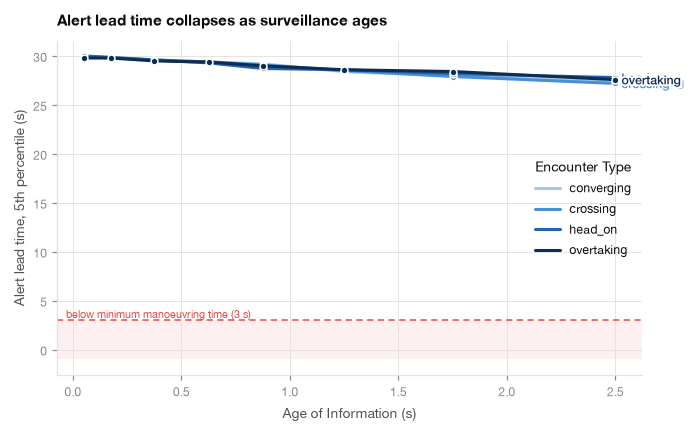

In [10]:
from telemetry_freshness.evaluation.metrics import bin_by_aoi

# Attach each encounter's realised median AoI to its timing outcome.
aoi_per_run = (E1.groupby(["encounter_type","update_rate_hz","latency_ms","seed_index"])
                 .aoi_s.median().rename("aoi_s").reset_index())
tm = timing.merge(aoi_per_run, on=["encounter_type","update_rate_hz","latency_ms","seed_index"])
binned = bin_by_aoi(tm.dropna(subset=["alert_lead_time_s"]))
curve = (binned.groupby(["encounter_type","aoi_bin"], observed=True)
         .agg(aoi_bin_mid=("aoi_bin_mid","first"),
              lead_time_p5_s=("alert_lead_time_s", lambda s: np.percentile(s, 5)),
              n=("alert_lead_time_s","size")).reset_index())
curve = curve[curve.n >= 5]

fig, ax = F.fig_lead_time_vs_aoi(curve, level_col="encounter_type", min_lead_s=3.0)
S.save(fig, "F4_lead_time_vs_aoi"); S.plt.show()
curve.to_csv("results/processed/E1_lead_time_by_aoi.csv", index=False)

> **Assumption.** The 3 s minimum manoeuvring time is an experiment parameter,
> not a regulatory value. It is carried explicitly so the threshold in
> notebook 06 can be re-derived under any other choice.